# AI-XRay · 01 — Exploración de datos (EDA), manifiesto y fuga de datos

**Proyecto Final Independiente · Clase 4 · Unidad 3** — Máster en IA & Data Science (DevSeniorCode)
Autor: **César Libardo España Salguero**

### Objetivo
1. Construir el **manifiesto** del dataset (ruta, etiqueta, paciente) juntando `train/` y `test/` originales.
2. EDA: balance de clases y origen de las imágenes.
3. Paso de **procesamiento masivo con PySpark** (el mismo código que correría en Databricks).
4. **Verificar la fuga de datos** a nivel paciente del split original — para PNEUMONIA *y* para NORMAL.
5. Subconjunto balanceado de 2,000 imágenes + **split propio 70/15/15 agrupado por paciente**.
6. Comprobar con un `assert` que ningún paciente queda en dos splits, y guardar el manifiesto.

> **Mejora propia respecto a la versión de clase:** en la versión original cada imagen NORMAL
> se trataba como un paciente distinto. Aquí se comprueba que el prefijo `IM-XXXX` agrupa
> varias radiografías del mismo estudio, y se usa para agrupar también la clase NORMAL.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Este notebook vive en AI-XRay/notebooks/; agregamos AI-XRay/ al path para importar `src`.
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import DATA_DIR, DEMO_SUBSET_PER_CLASS, MANIFEST_PATH, SPLIT_MANIFEST_PATH, SEED
from src.dataset import _extract_patient_id, build_manifest, make_balanced_subset, split_manifest

print("Buscando el dataset en:", DATA_DIR)

Buscando el dataset en: /home/claude/work/archive (2)/Pediatric Chest X-ray Pneumonia


## 1. Manifiesto completo (train + test originales, juntos)

In [2]:
manifest = build_manifest(DATA_DIR)
print(f"Total de imágenes encontradas: {len(manifest):,}")
manifest[["filename", "label", "label_name", "patient_id", "origin_split"]].head()

Total de imágenes encontradas: 5,856


,filename,label,label_name,patient_id,origin_split
0,IM-0115-0001.png,0,NORMAL,normal_IM-0115,train
1,IM-0117-0001.png,0,NORMAL,normal_IM-0117,train
2,IM-0119-0001.png,0,NORMAL,normal_IM-0119,train
3,IM-0122-0001.png,0,NORMAL,normal_IM-0122,train
4,IM-0125-0001.png,0,NORMAL,normal_IM-0125,train


In [3]:
print("Por clase:")
print(manifest["label_name"].value_counts())
print("\nPor carpeta de origen (informativo -- NO es el split que vamos a usar):")
print(manifest.groupby(["origin_split", "label_name"]).size())

Por clase:
label_name
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Por carpeta de origen (informativo -- NO es el split que vamos a usar):


origin_split  label_name
test          NORMAL         234
              PNEUMONIA      390
train         NORMAL        1349
              PNEUMONIA     3883
dtype: int64


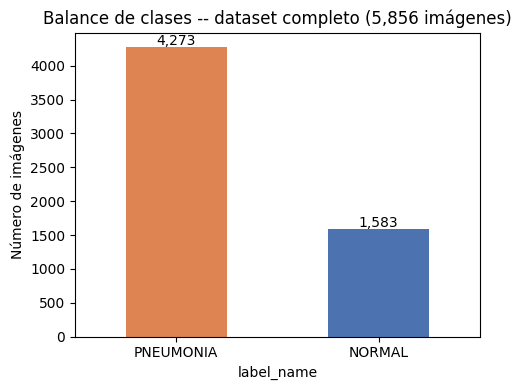

Desbalance PNEUMONIA:NORMAL = 2.70 : 1


In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = manifest["label_name"].value_counts()
counts.plot(kind="bar", ax=ax, color=["#DD8452", "#4C72B0"])
ax.set_title(f"Balance de clases -- dataset completo ({len(manifest):,} imágenes)")
ax.set_ylabel("Número de imágenes")
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v:,}", ha="center")
plt.tight_layout()
plt.show()
print(f"Desbalance PNEUMONIA:NORMAL = {counts['PNEUMONIA'] / counts['NORMAL']:.2f} : 1")

## 2. Procesamiento masivo (PySpark)

Con 5,856 imágenes esto es simbólico (no se necesita un cluster), pero el código es el mismo que
se usaría sobre un Data Lake con cientos de miles de imágenes en Databricks
(`spark.read.format("binaryFile")`). Además de contar, se usa Spark para una agregación real:
el tamaño medio de archivo por clase y carpeta de origen.

In [5]:
try:
    from pyspark.sql import functions as F
    from src.dataset import build_manifest_spark

    manifest_spark = build_manifest_spark(DATA_DIR)
    print("Filas (Spark):", manifest_spark.count(), "| Filas (pandas):", len(manifest))
    (manifest_spark.groupBy("origin_split", "label_name")
        .agg(F.count("*").alias("imagenes"),
             F.round(F.avg("file_size_bytes") / 1024, 1).alias("kb_promedio"),
             F.countDistinct("patient_id").alias("pacientes"))
        .orderBy("origin_split", "label_name")
        .show())
    manifest_spark.sparkSession.stop()
except ImportError:
    print("PySpark no está instalado en este entorno -- paso opcional, se omite.")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/08 13:25:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Filas (Spark): 5856 | Filas (pandas): 5856


+------------+----------+--------+-----------+---------+
|origin_split|label_name|imagenes|kb_promedio|pacientes|
+------------+----------+--------+-----------+---------+
|        test|    NORMAL|     234|       70.4|      225|
|        test| PNEUMONIA|     390|       60.3|      202|
|       train|    NORMAL|    1349|       79.4|     1219|
|       train| PNEUMONIA|    3883|       61.3|     1642|
+------------+----------+--------+-----------+---------+



## 3. Fuga de datos a nivel paciente (por qué no usamos el split original)

**PNEUMONIA:** los archivos siguen el patrón `personNNNN_{bacteria|virus}_MMMM` — `NNNN` es el paciente.

In [6]:
pneumonia = manifest[manifest["label_name"] == "PNEUMONIA"]
patient_splits = pneumonia.groupby("patient_id")["origin_split"].nunique()
patients_leaked = patient_splits[patient_splits > 1]
imgs_leaked = pneumonia[pneumonia["patient_id"].isin(patients_leaked.index)]

print(f"Pacientes PNEUMONIA: {pneumonia['patient_id'].nunique():,}")
print(f"Pacientes con imágenes en train Y test original: {len(patients_leaked)} "
      f"({len(patients_leaked) / pneumonia['patient_id'].nunique():.1%})")
print(f"Imágenes de test original que pertenecen a un paciente también visto en train: "
      f"{(imgs_leaked['origin_split'] == 'test').sum()} de {(pneumonia['origin_split'] == 'test').sum()}")
ejemplo = "pneumonia_100" if "pneumonia_100" in patients_leaked.index else patients_leaked.index[0]
print(f"\nEjemplo real: '{ejemplo}' aparece en:")
pneumonia[pneumonia["patient_id"] == ejemplo][["filename", "origin_split"]]

Pacientes PNEUMONIA: 1,674
Pacientes con imágenes en train Y test original: 170 (10.2%)
Imágenes de test original que pertenecen a un paciente también visto en train: 320 de 390

Ejemplo real: 'pneumonia_100' aparece en:


,filename,origin_split
1365,person100_virus_184.png,train
5466,person100_bacteria_475.png,test
5467,person100_bacteria_477.png,test
5468,person100_bacteria_478.png,test
5469,person100_bacteria_479.png,test
5470,person100_bacteria_480.png,test
5471,person100_bacteria_481.png,test
5472,person100_bacteria_482.png,test


**NORMAL:** los archivos se llaman `IM-XXXX-NNNN` o `NORMAL2-IM-XXXX-NNNN`. Si el prefijo `IM-XXXX`
identifica un estudio, varias imágenes deberían compartirlo. Lo comprobamos comparando la agrupación
original (1 imagen = 1 "paciente") con la agrupación por prefijo.

In [7]:
normal = manifest[manifest["label_name"] == "NORMAL"].copy()
normal["id_original"] = [_extract_patient_id(f, "NORMAL", group_normal=False) for f in normal["filename"]]
grupos = normal["patient_id"].value_counts()

print(f"Imágenes NORMAL: {len(normal):,}")
print(f"IDs con la agrupación original (1 imagen = 1 id): {normal['id_original'].nunique():,}")
print(f"IDs agrupando por prefijo IM-XXXX:              {normal['patient_id'].nunique():,}")
print(f"Estudios NORMAL con más de 1 imagen: {(grupos > 1).sum()} "
      f"({normal['patient_id'].isin(grupos[grupos > 1].index).sum()} imágenes)")
print(f"Estudios NORMAL repartidos entre train y test original: "
      f"{(normal.groupby('patient_id')['origin_split'].nunique() > 1).sum()}")
print("\nEjemplo: el estudio con más imágenes")
normal[normal["patient_id"] == grupos.index[0]][["filename", "origin_split", "patient_id"]]

Imágenes NORMAL: 1,583
IDs con la agrupación original (1 imagen = 1 id): 1,583
IDs agrupando por prefijo IM-XXXX:              1,444
Estudios NORMAL con más de 1 imagen: 75 (214 imágenes)
Estudios NORMAL repartidos entre train y test original: 0

Ejemplo: el estudio con más imágenes


,filename,origin_split,patient_id
383,IM-0553-0001-0001.png,train,normal_IM-0553
384,IM-0553-0001-0002.png,train,normal_IM-0553
385,IM-0553-0001-0003.png,train,normal_IM-0553
386,IM-0553-0001.png,train,normal_IM-0553


**Conclusión:**
- En PNEUMONIA la fuga es real: 170 pacientes tienen imágenes en `train/` y `test/` original.
  Evaluar con ese split sobreestimaría el desempeño.
- En NORMAL no hay fuga en el split original, pero 75 estudios tienen varias imágenes
  (p. ej. `IM-0553-0001`, `-0001-0001`, `-0001-0002`…). Con la agrupación original, un split propio
  al azar **sí** podía repartirlas entre train y test. Agruparlas por prefijo cierra ese hueco.
- Por eso se descarta `origin_split` y se construye un split propio agrupado por paciente/estudio.

## 4. Subconjunto balanceado (2,000 imágenes)

In [8]:
subset = make_balanced_subset(manifest, per_class=DEMO_SUBSET_PER_CLASS, seed=SEED)
print(f"Subconjunto: {len(subset):,} imágenes")
print(subset["label_name"].value_counts())

Subconjunto: 2,000 imágenes
label_name
PNEUMONIA    1000
NORMAL       1000
Name: count, dtype: int64


## 5. Split propio 70/15/15, agrupado por paciente

In [9]:
split = split_manifest(subset)
tabla = split.groupby(["split", "label_name"]).size().unstack()
tabla["total"] = tabla.sum(axis=1)
tabla

label_name,NORMAL,PNEUMONIA,total
split,,,
test,146,156,302
train,701,688,1389
val,153,156,309


In [10]:
# Verificación: ningún paciente/estudio debe aparecer en más de un split.
leakage_check = split.groupby("patient_id")["split"].nunique()
n_leaked = int((leakage_check > 1).sum())
print(f"Pacientes repartidos entre más de un split (debe ser 0): {n_leaked}")
assert n_leaked == 0, "¡Hay fuga de datos en el split! Revisa split_manifest()."

# Contraprueba: ¿qué habría pasado con la agrupación original de NORMAL (1 imagen = 1 id)?
from src.dataset import split_manifest as _split
naive = subset.copy()
naive["patient_id"] = [_extract_patient_id(f, l, group_normal=False) for f, l in zip(naive["filename"], naive["label_name"])]
naive = _split(naive)
naive["estudio"] = [_extract_patient_id(f, l) for f, l in zip(naive["filename"], naive["label_name"])]
fuga_naive = int((naive.groupby("estudio")["split"].nunique() > 1).sum())
print(f"Con la agrupación ORIGINAL, estudios NORMAL que habrían quedado partidos entre splits: {fuga_naive}")
print("OK -- split propio sin fuga de datos a nivel paciente/estudio.")

Pacientes repartidos entre más de un split (debe ser 0): 0
Con la agrupación ORIGINAL, estudios NORMAL que habrían quedado partidos entre splits: 29
OK -- split propio sin fuga de datos a nivel paciente/estudio.


## 6. Guardar el manifiesto

In [11]:
MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
manifest.to_csv(MANIFEST_PATH, index=False)
split.to_csv(SPLIT_MANIFEST_PATH, index=False)
print("Guardado:")
print(" -", MANIFEST_PATH.relative_to(PROJECT_ROOT), f"({len(manifest):,} filas)")
print(" -", SPLIT_MANIFEST_PATH.relative_to(PROJECT_ROOT), f"({len(split):,} filas)")

Guardado:
 - data/manifest.csv (5,856 filas)
 - data/manifest_split.csv (2,000 filas)


Siguiente: `02_preprocessing.ipynb`.